# Encoder-Decoder Architecture which :
1. Encodes an input sequence into a fixed-size context vector
2. Decodes this context to generate an output sequence of different length

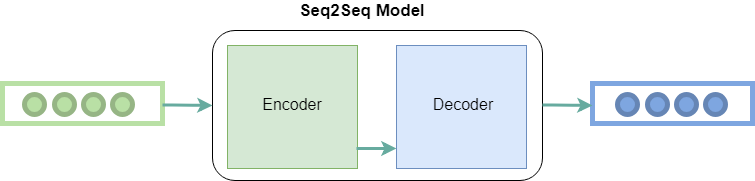

In [ ]:
import torch
import torch.nn as nn

In [342]:
total_tokens = 20
input_dim = output_dim = total_tokens
emb_dim = 8
hid_dim = 16

In [343]:
class Encoder(nn.Module):
    def __init__(self, input_dim, emb_dim, hid_dim):
        super().__init__()
        self.embedding = nn.Embedding(input_dim, embedding_dim=emb_dim) # Embedding the input token (Get a vector of token)
        self.rnn = nn.LSTM(emb_dim, hidden_size=hid_dim, batch_first=True) # LSTM as nn

    
    def forward(self, inp_token):
        embedded = self.embedding(inp_token) # Get embedded vector of the input token
        outputs, hidden_state = self.rnn(embedded) # Produces all outputs for each token with hidden statess
        return hidden_state # Last hidden state (contains short-term memeory/ context of the input sequence) is required for decoder to predict next word

In [344]:
class Decoder(nn.Module):
    def __init__(self, output_dim, emb_dim, hid_dim):
        super().__init__()
        self.embedding = nn.Embedding(output_dim, embedding_dim=emb_dim) # Embedding the output token (Get a vector of token)
        self.rnn = nn.LSTM(emb_dim, hidden_size=hid_dim, batch_first=True)
        self.logits = nn.Linear(hid_dim, output_dim) # Creates a whole NN and ouputs the logits (scores of possible next words) of predicted next word according to the hidden_state provided by LSTM
    
    def forward(self, decoder_input, hidden_state):
        decoder_input = decoder_input.unsqueeze(1) # Adds extra dimension to the decoder_input token
        embedded = self.embedding(decoder_input) # Embedding the decoder_input to correct vector form
        output, hidden_state = self.rnn(embedded, hidden_state) # get all the hidden states from the LSTM
        prediction = self.logits(output.squeeze(1)) # Remove a single dimension from the output to make it 1D
        return prediction, hidden_state

In [345]:
class Seq2SeqModel(nn.Module):
    def __init__(self, encoder, decoder):
        super().__init__()
        # Bind the object with encoder and decoder
        self.encoder = encoder
        self.decoder = decoder

    
    def forward(self, inp_token, target_token):
        # Creating the placeholder for target next word
        batch_size, target_token_len = target_token.shape
        outputs = torch.zeros(target_token_len, batch_size, total_tokens)

        # Pass input token through encoder to get the last hidden state
        hidden_state = self.encoder(inp_token)
        decoder_input = target_token[: , 0] # Create start of sentence <sos> to pass through decoder

        for trg in range(1, target_token_len):
            output, hidden_state = self.decoder(decoder_input, hidden_state) # Passes decoder's input and hidden state from encoder to decoder
            outputs[trg] = output
            decoder_input = target_token[:, trg] # Teacher forcing for next input means using the target token for next input to the decoder not model its own prediction
        return outputs

In [346]:
encoder = Encoder(input_dim=input_dim, emb_dim=emb_dim, hid_dim=hid_dim)
decoder = Decoder(output_dim=output_dim, hid_dim=hid_dim, emb_dim=emb_dim)
model = Seq2SeqModel(encoder=encoder, decoder=decoder)

In [347]:
# Suppose an input sequence of words and its target 
input_word = torch.tensor([[2, 5, 7]])      
target_word = torch.tensor([[1, 10, 12, 15]])

In [348]:
outputs = model(input_word, target_word)

In [349]:
predicted_tokens = outputs.argmax(dim=2).squeeze(1)[1:] # Get the maximum score amoung the outputs indices

In [350]:
predicted_tokens

tensor([0, 0, 0])